## Functions

In [ ]:
#functions
def load(fimo):
  import pandas as pd

  # load FIMO output
  df = pd.read_csv(fimo, sep="\t", comment="#")

  # keep significant hits (adjust threshold as needed)
  df = df[df["p-value"] < 1e-4]

  # build presence table
  presence = (
      df.groupby(["sequence_name", "motif_id"])
        .size()
        .unstack(fill_value=0)
  )

  # convert counts → binary (presence/absence)
  presence = (presence > 0).astype(int)

  print(presence.head())
  return presence

In [ ]:
#basic stats
#no of motifs, no of sequences
def stats(fimo):
    import pandas as pd

    # load FIMO output
    df = pd.read_csv(fimo, sep="\t", comment="#")

    #no of motifs
    no=len(df["motif_id"].unique())
    print("No of motifs:",no)

    #no of prom seq
    seq=len(df["sequence_name"].unique())
    print("No of sequences:",seq)

In [ ]:
def matrix(presence):
    #co-occurence matrix
    import numpy as np

    n = presence.shape[0]

    co_matrix = np.dot(presence.T, presence)
    percent_matrix = (co_matrix / n) * 100

    co_df = pd.DataFrame(
        percent_matrix,
        index=presence.columns,
        columns=presence.columns
    )
    return co_df

In [ ]:
#heatmap
def heatmap(co_df):
    import seaborn as sns
    import matplotlib.pyplot as plt

    plt.figure(figsize=(20,18)) # Increased figure size for better readability
    sns.heatmap(co_df, annot=True, cmap="magma", fmt=".1f", annot_kws={"fontsize":8}) # Reduced annotation font size
    plt.title("Motif Co-occurrence (%)", fontsize=16, pad=20) # Centered title and increased font size
    plt.tight_layout() # Adjust layout to prevent labels from being cut off
    plt.show()

In [ ]:
#heatmap
def heatmap2(co_df):
    import seaborn as sns
    import matplotlib.pyplot as plt

    plt.figure(figsize=(20,18)) # Increased figure size for better readability
    #no decimals
    co_df = co_df.round(0)
    sns.heatmap(co_df, annot=True, cmap="magma", annot_kws={"fontsize":8}) # Reduced annotation font size
    plt.title("Motif Co-occurrence (%)", fontsize=16, pad=20) # Centered title and increased font size
    plt.tight_layout() # Adjust layout to prevent labels from being cut off
    plt.show()

## Output

motif_id       1-CCACCACGCCCGGCY  10-AAAAAAAAAAAAAAA  11-AAAATACAAAAAT  \
sequence_name                                                            
AAGAB(-)                       1                   0                 1   
AANAT(+)                       1                   1                 1   
ABHD16A(-)                     1                   1                 1   
ABHD4(+)                       1                   1                 1   
ACACA(-)                       1                   1                 1   

motif_id       12-AGTGCAGTGGCG  13-GCAACCTCCGCCTCC  14-CAVGTGATC  \
sequence_name                                                      
AAGAB(-)                     0                   1             0   
AANAT(+)                     1                   1             1   
ABHD16A(-)                   1                   1             1   
ABHD4(+)                     1                   1             1   
ACACA(-)                     1                   1             1   

moti

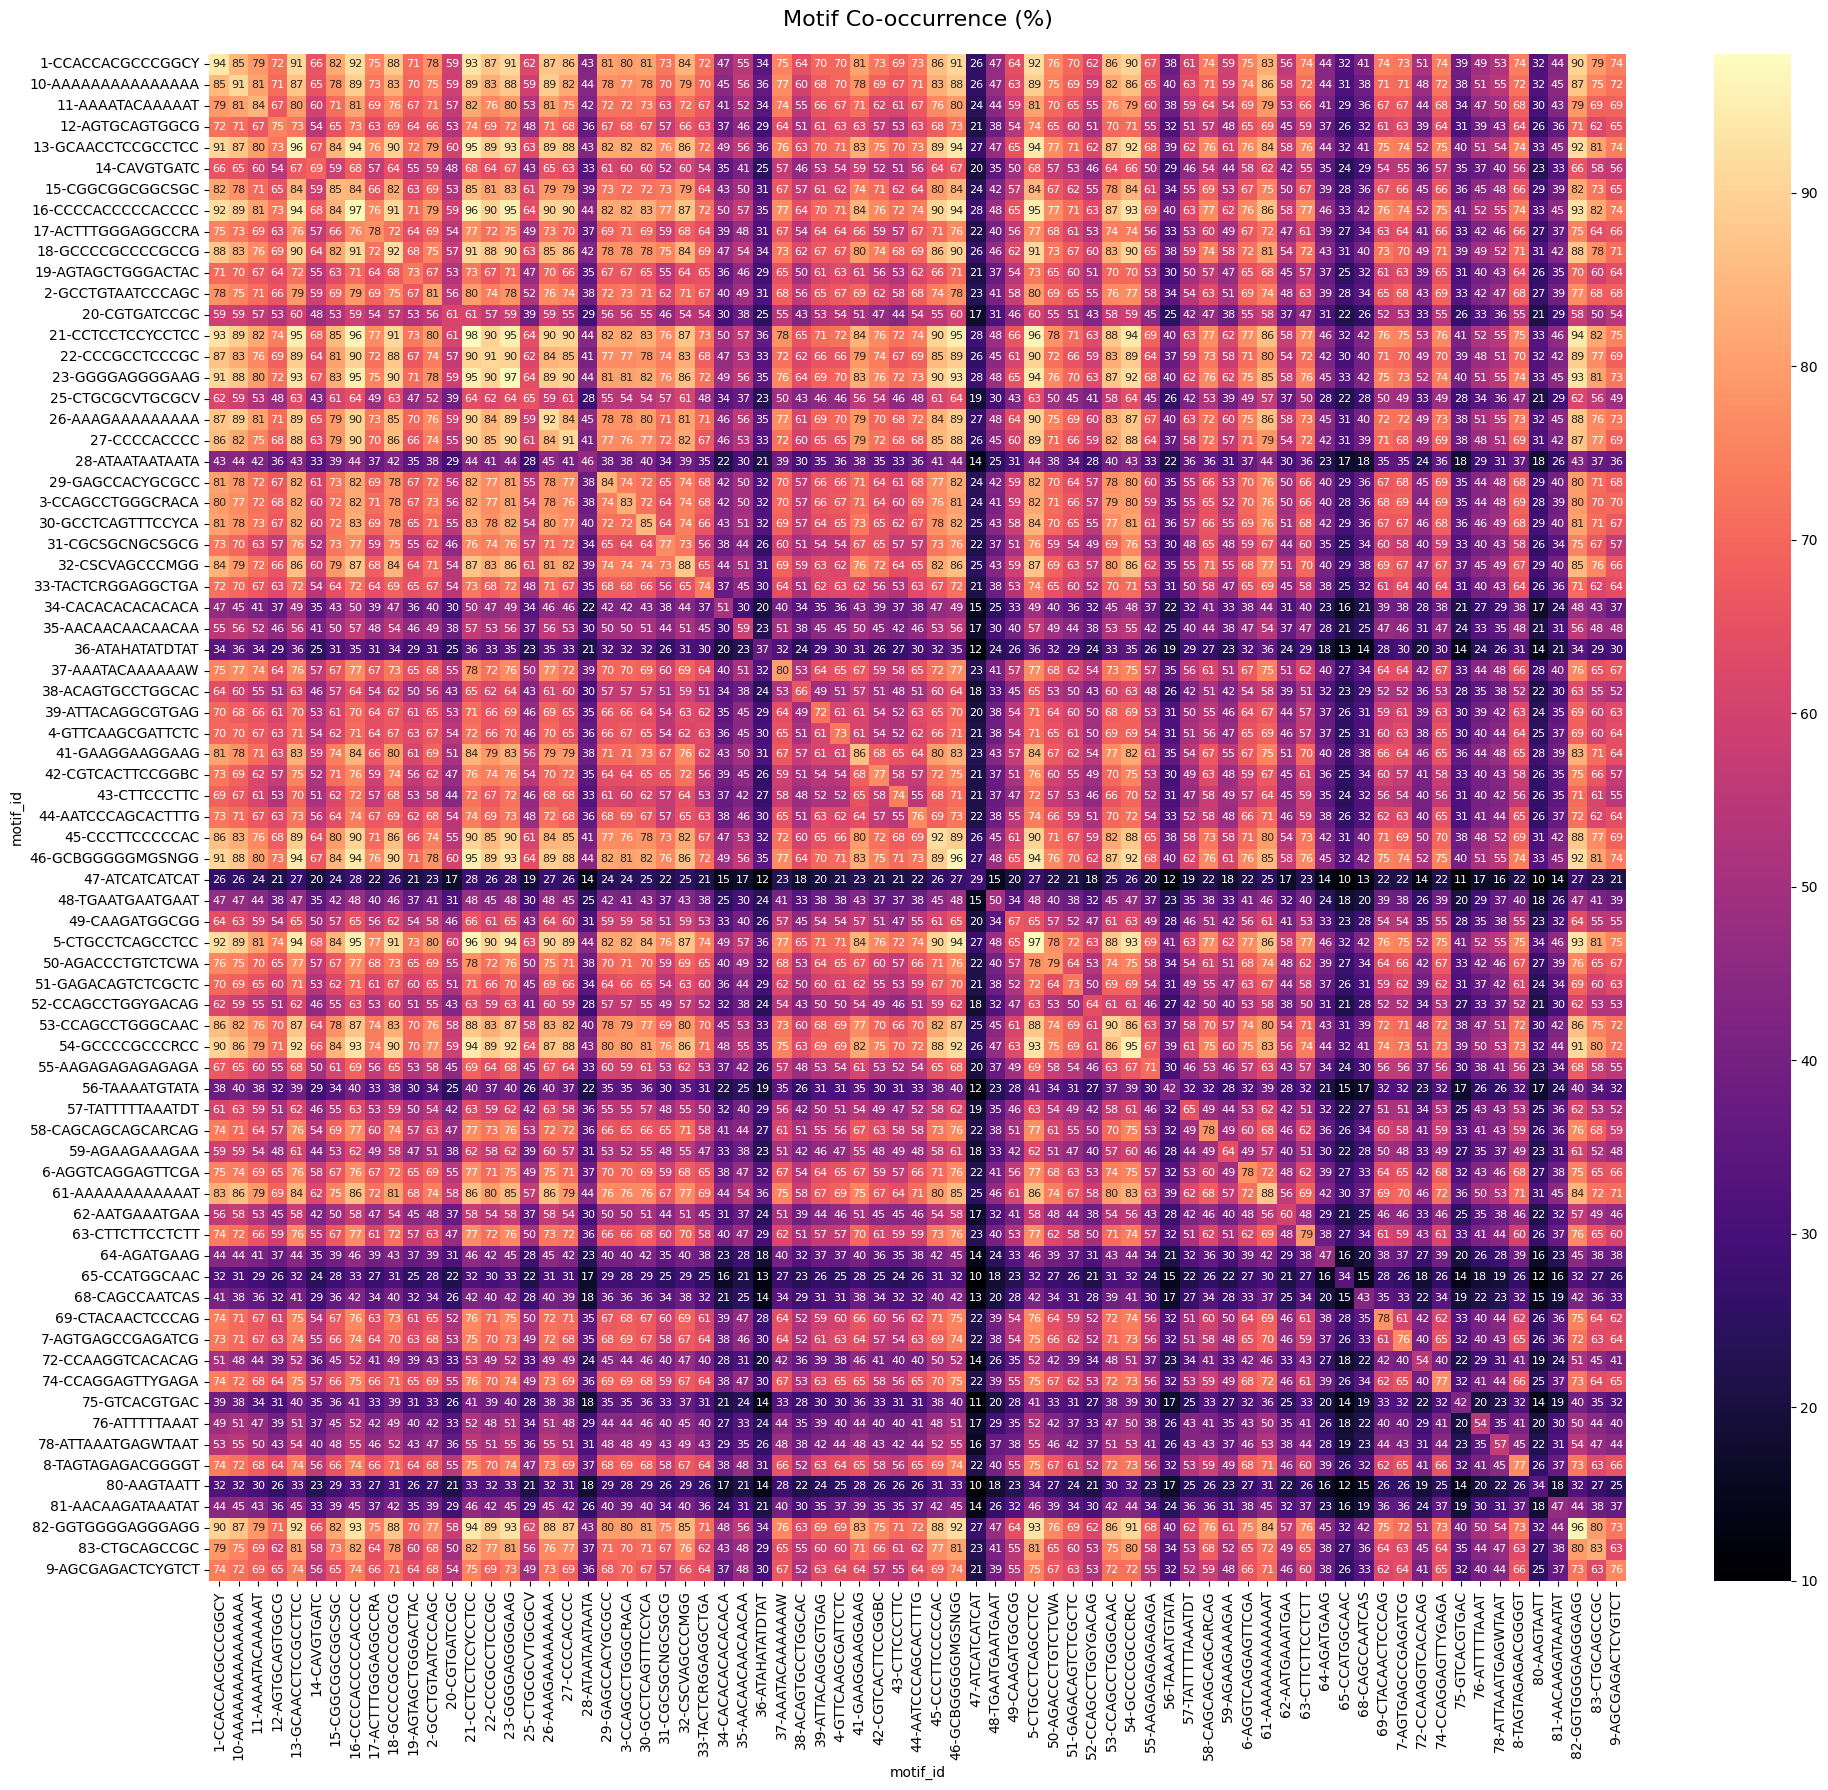

In [ ]:
#SREBF1
filepath="/content/fimo.tsv"
pre=load(filepath)
mat=matrix(pre)
heatmap2(mat)

In [ ]:
#SREBF2
filepath2="/content/SREBF2_fimo.tsv"
pre2=load(filepath2)
mat2=matrix(pre2)

motif_id       1-AGACCAGCCTGGCC  2-GATTACAGGCRTGAG  5-CTGCCTCAGCCTCCY
sequence_name                                                        
ALKBH7(+)                     1                  1                  1
ALOX12B(-)                    1                  1                  1
AMACR(-)                      1                  1                  1
BRIX1(+)                      1                  1                  1
CCDC107(+)                    1                  1                  1


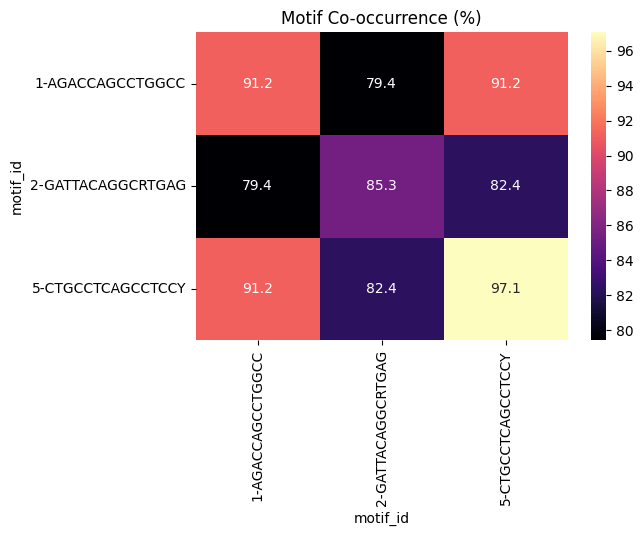

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
sns.heatmap(mat2, annot=True, cmap="magma", fmt=".1f")
plt.title("Motif Co-occurrence (%)")
plt.show()

motif_id       1-CGGTGGCTCACGC  10-CCCCACCCCCCSSC  11-TCAAAAAAAAAAAAA  \
sequence_name                                                           
APTX(-)                      1                  1                   0   
C19orf25(-)                  1                  1                   1   
C6orf62(-)                   1                  1                   1   
CAVIN1(-)                    1                  1                   1   
CHAF1A(+)                    1                  1                   1   

motif_id       13-TCTCTACTAA  14-CCTCAGCCTCCCAAA  15-AAAAAAAAAAAAA  \
sequence_name                                                        
APTX(-)                    0                   1                 1   
C19orf25(-)                1                   1                 1   
C6orf62(-)                 1                   1                 1   
CAVIN1(-)                  1                   1                 1   
CHAF1A(+)                  1                   1                 1  

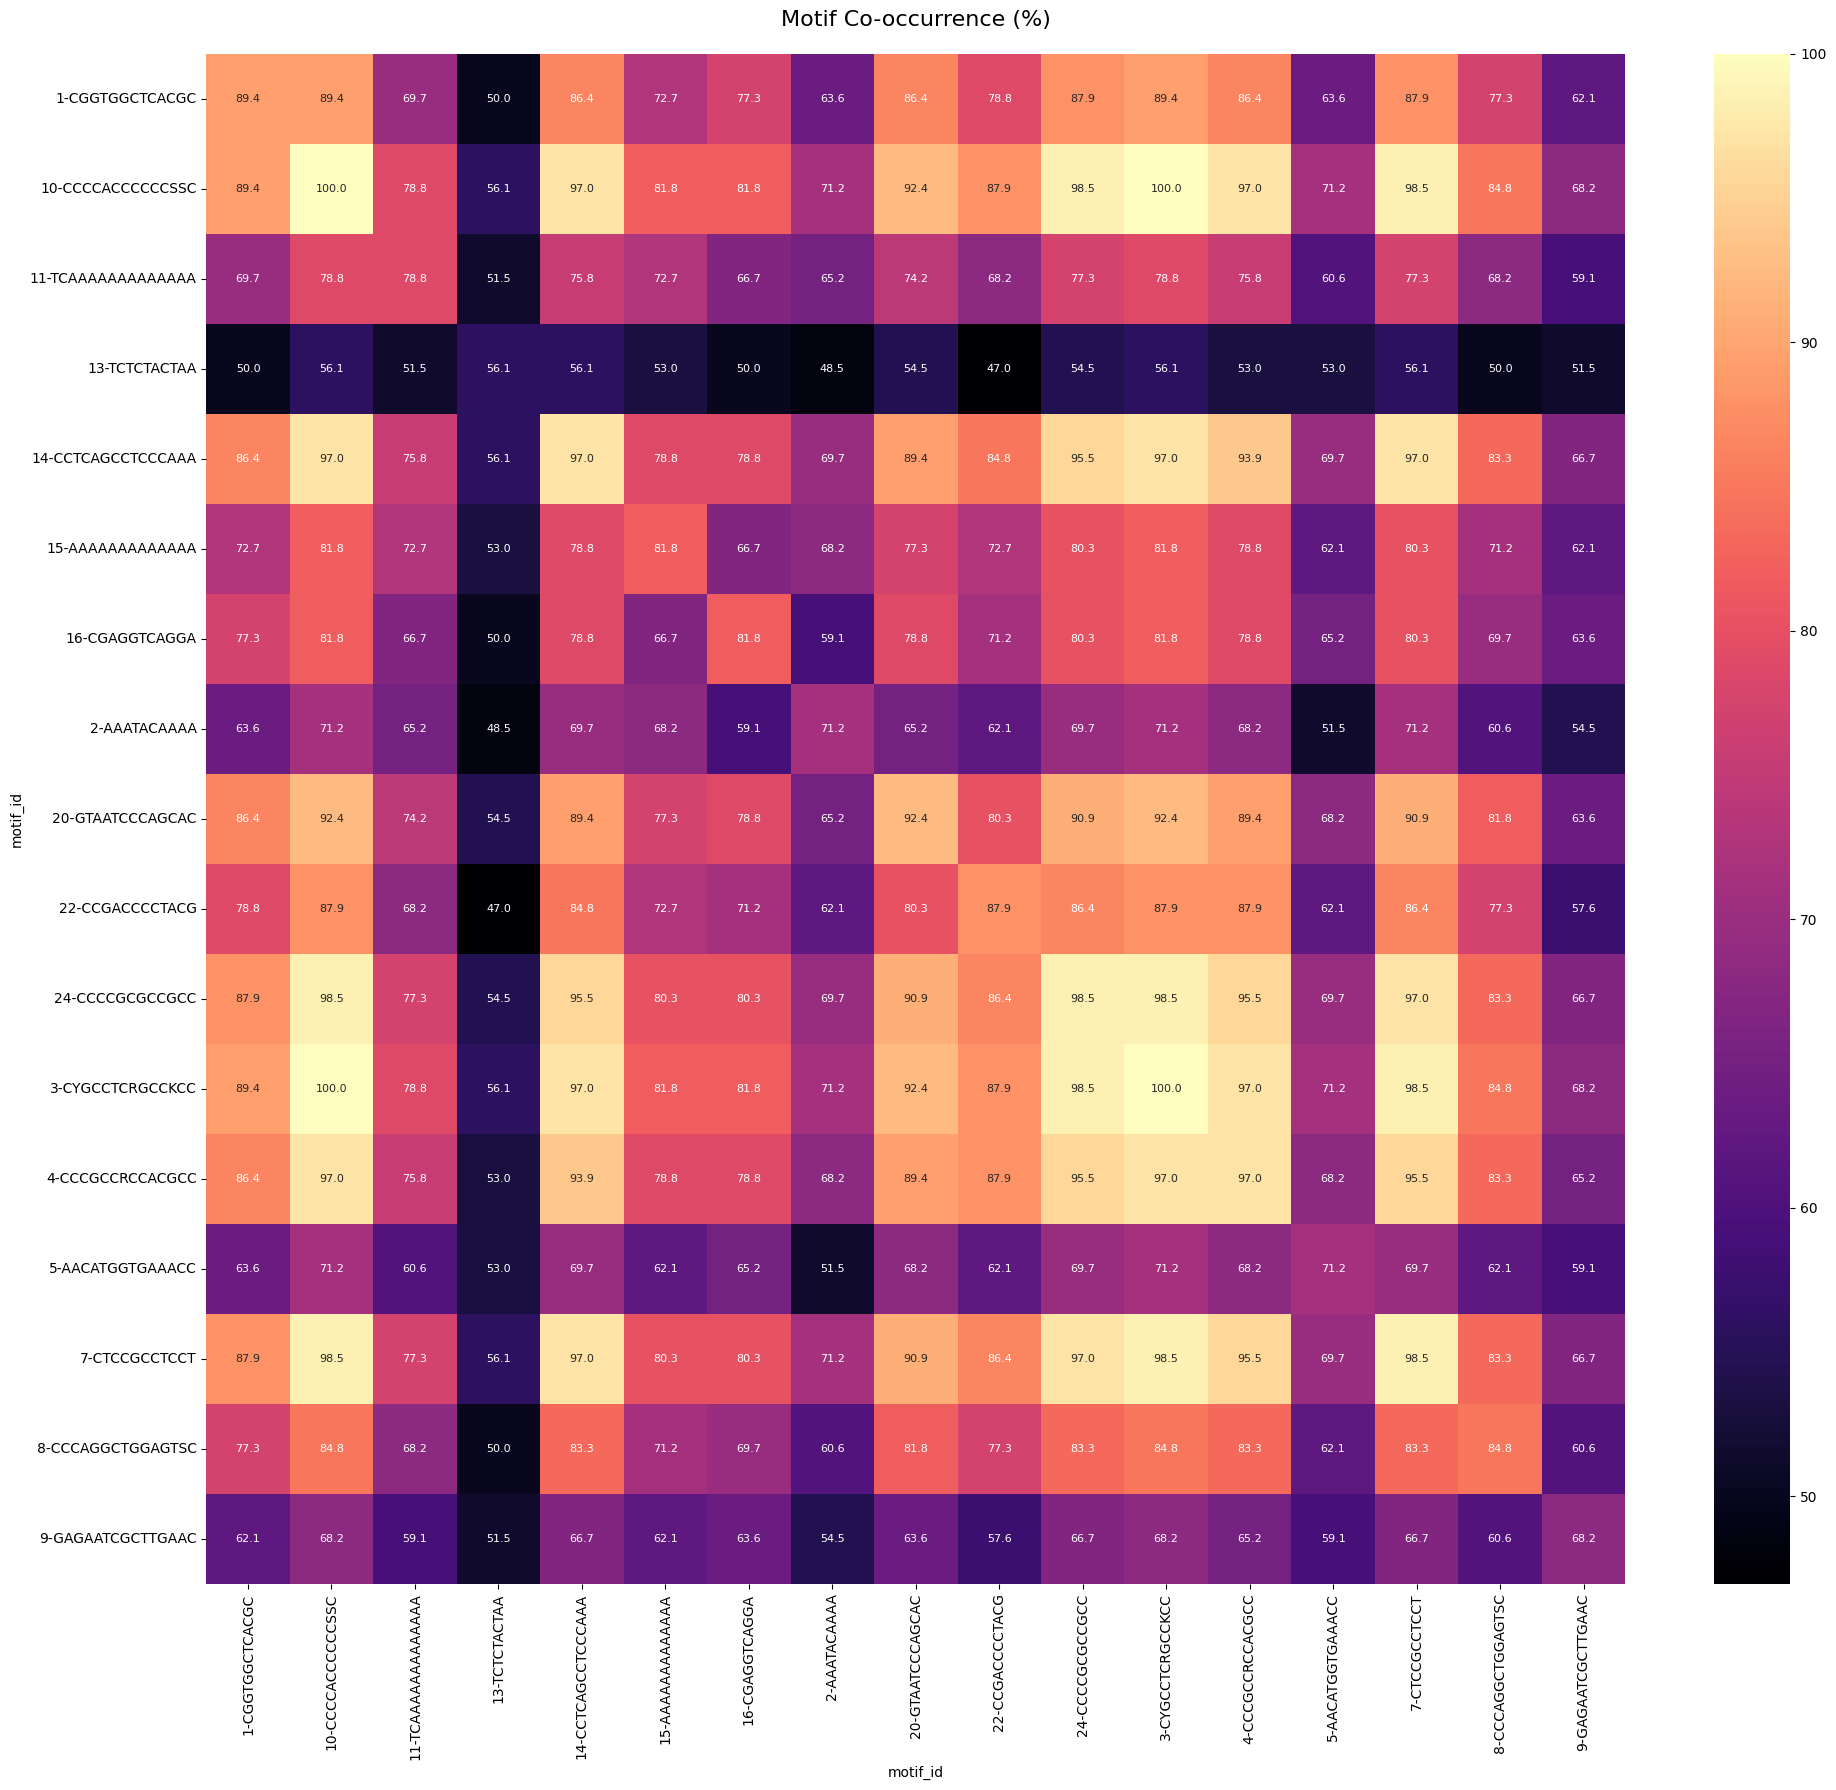

In [ ]:
#SREBF1-2
filepath3="/content/SREBF1-2_fimo.tsv"
pre3=load(filepath3)
mat3=matrix(pre3)
heatmap(mat3)

In [ ]:
#heatmap
def heatmap_dia2(co_df):
    import seaborn as sns
    import matplotlib.pyplot as plt
    import numpy as np

    #no decimals
    co_df = co_df.round(0)
    #print only one half as it's mirror, excluding the diagonal from the mask
    mask = np.triu(np.ones_like(co_df, dtype=bool), k=1)
    plt.figure(figsize=(20,18)) # Increased figure size for better readability
    sns.heatmap(co_df, annot=True, cmap="magma", annot_kws={"fontsize":8}, mask=mask) # Reduced annotation font size
    plt.title("Motif Co-occurrence (%) SREBF1", fontsize=16, pad=20) # Centered title and increased font size
    plt.tight_layout() # Adjust layout to prevent labels from being cut off
    plt.show()

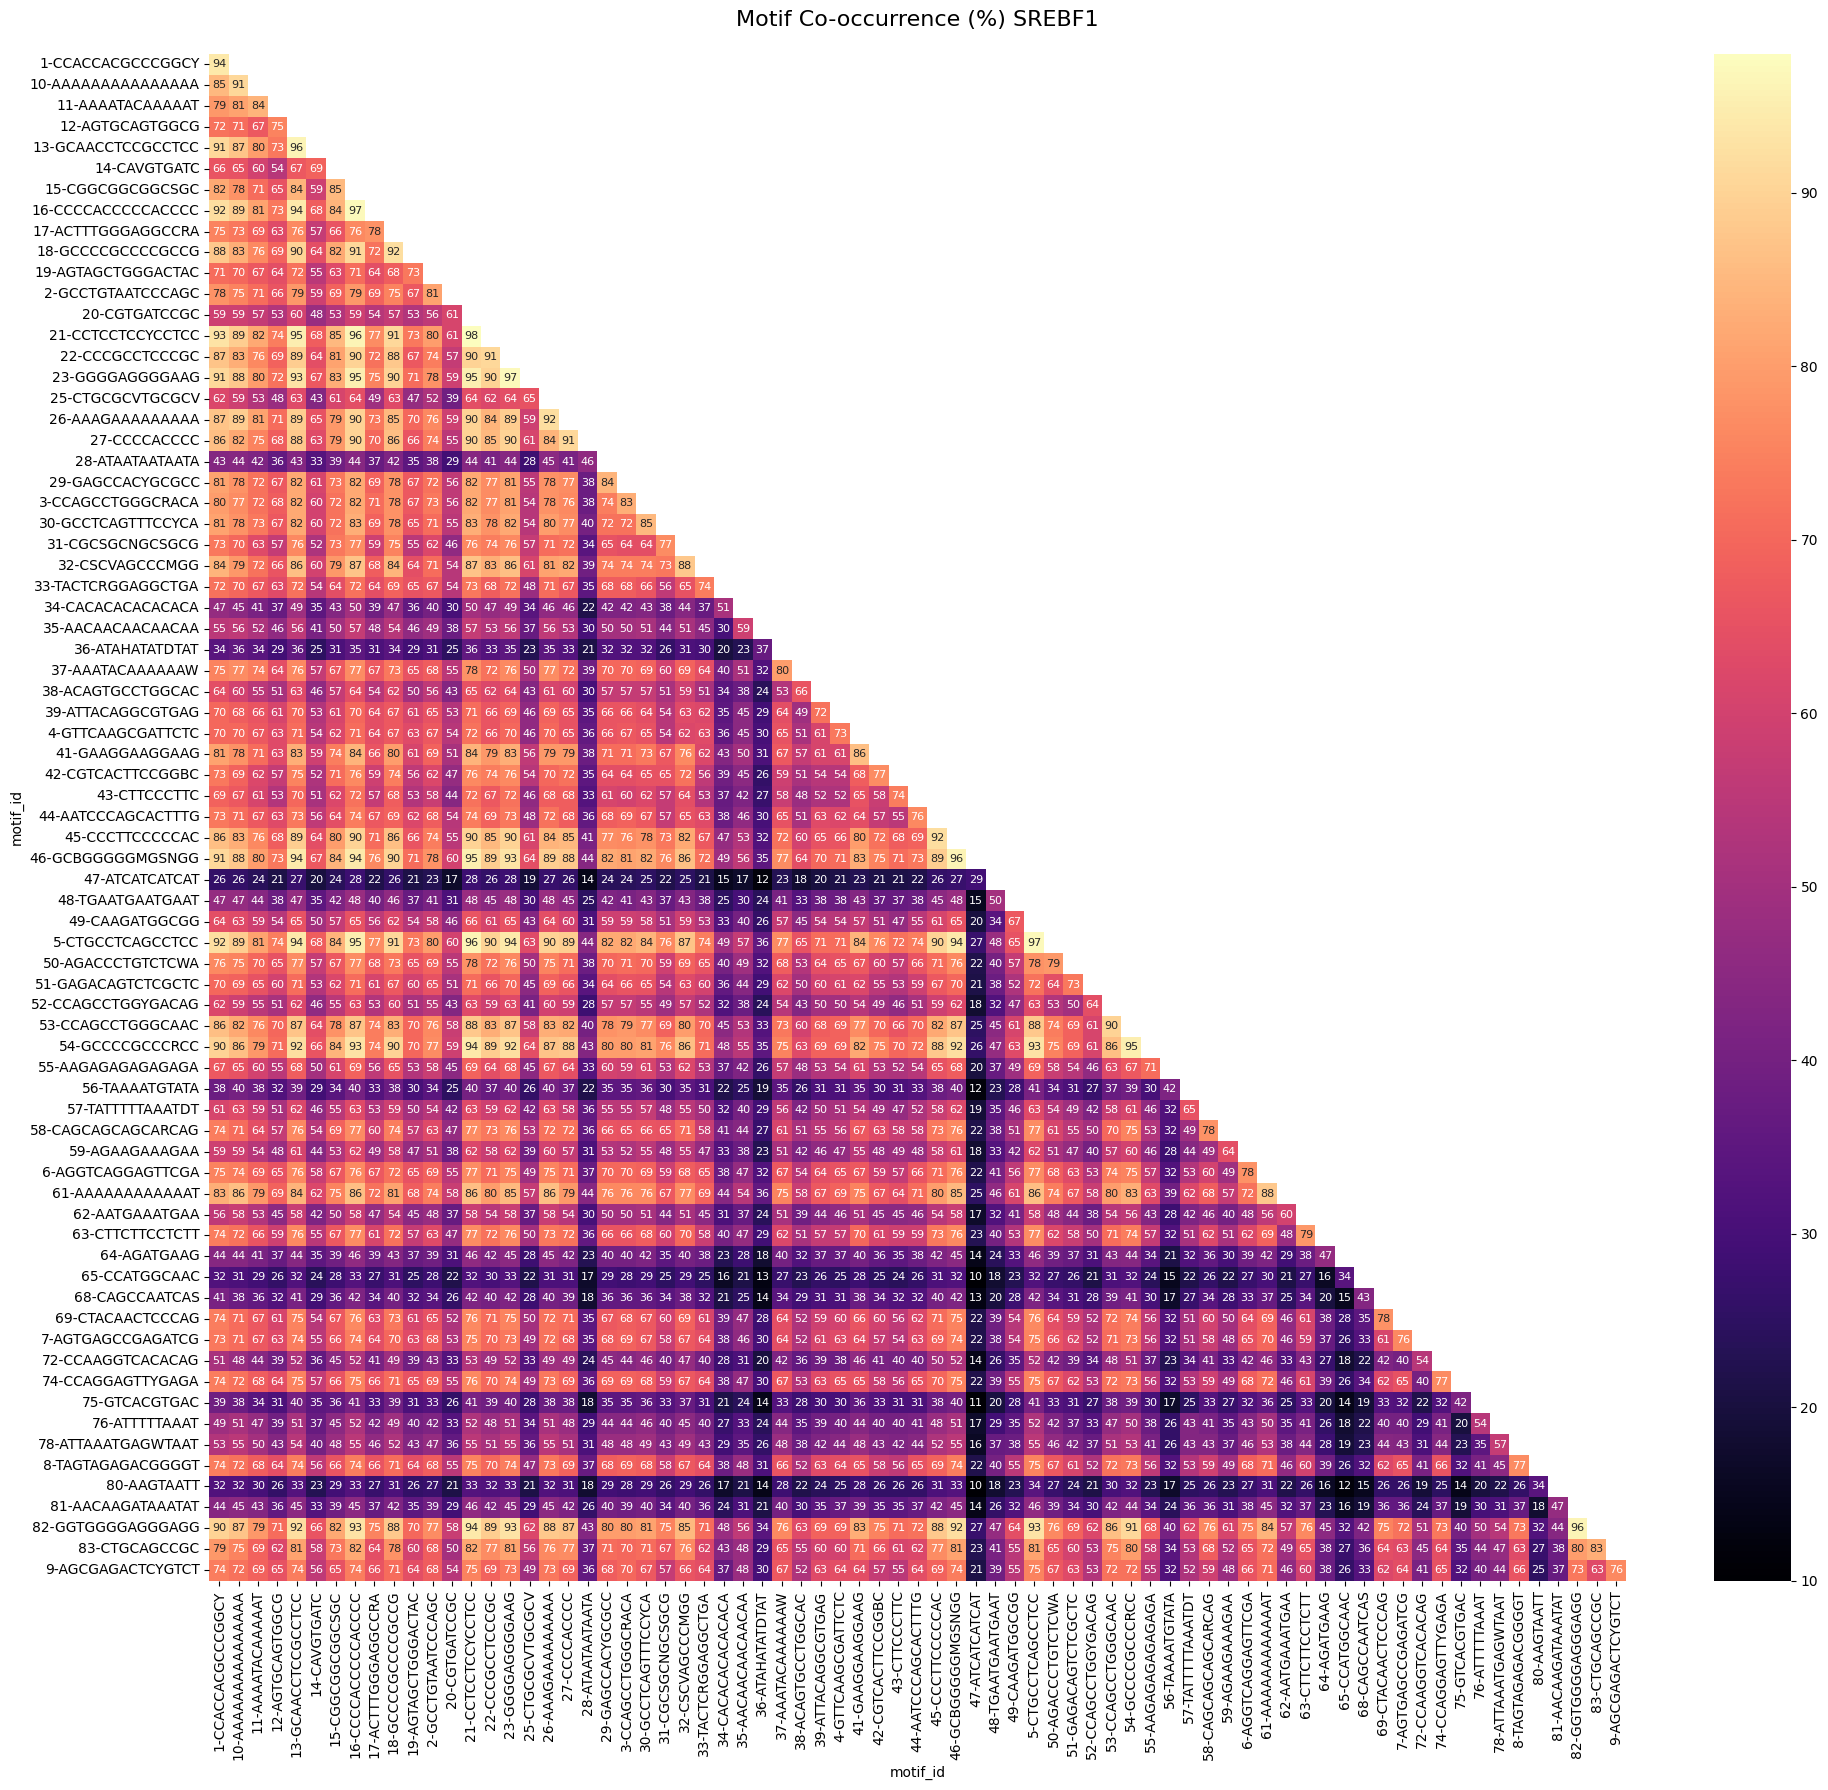

In [ ]:
heatmap_dia2(mat)

In [ ]:
#heatmap
def heatmap_dia(co_df):
    import seaborn as sns
    import matplotlib.pyplot as plt
    import numpy as np

    #print only one half as it's mirror, excluding the diagonal from the mask
    mask = np.triu(np.ones_like(co_df, dtype=bool), k=1)
    plt.figure(figsize=(20,18)) # Increased figure size for better readability
    sns.heatmap(co_df, annot=True, cmap="magma", fmt=".1f", annot_kws={"fontsize":8}, mask=mask) # Reduced annotation font size
    plt.title("Motif Co-occurrence (%) SREBF1 and SREBF2", fontsize=16, pad=20) # Centered title and increased font size
    plt.tight_layout() # Adjust layout to prevent labels from being cut off
    plt.show()

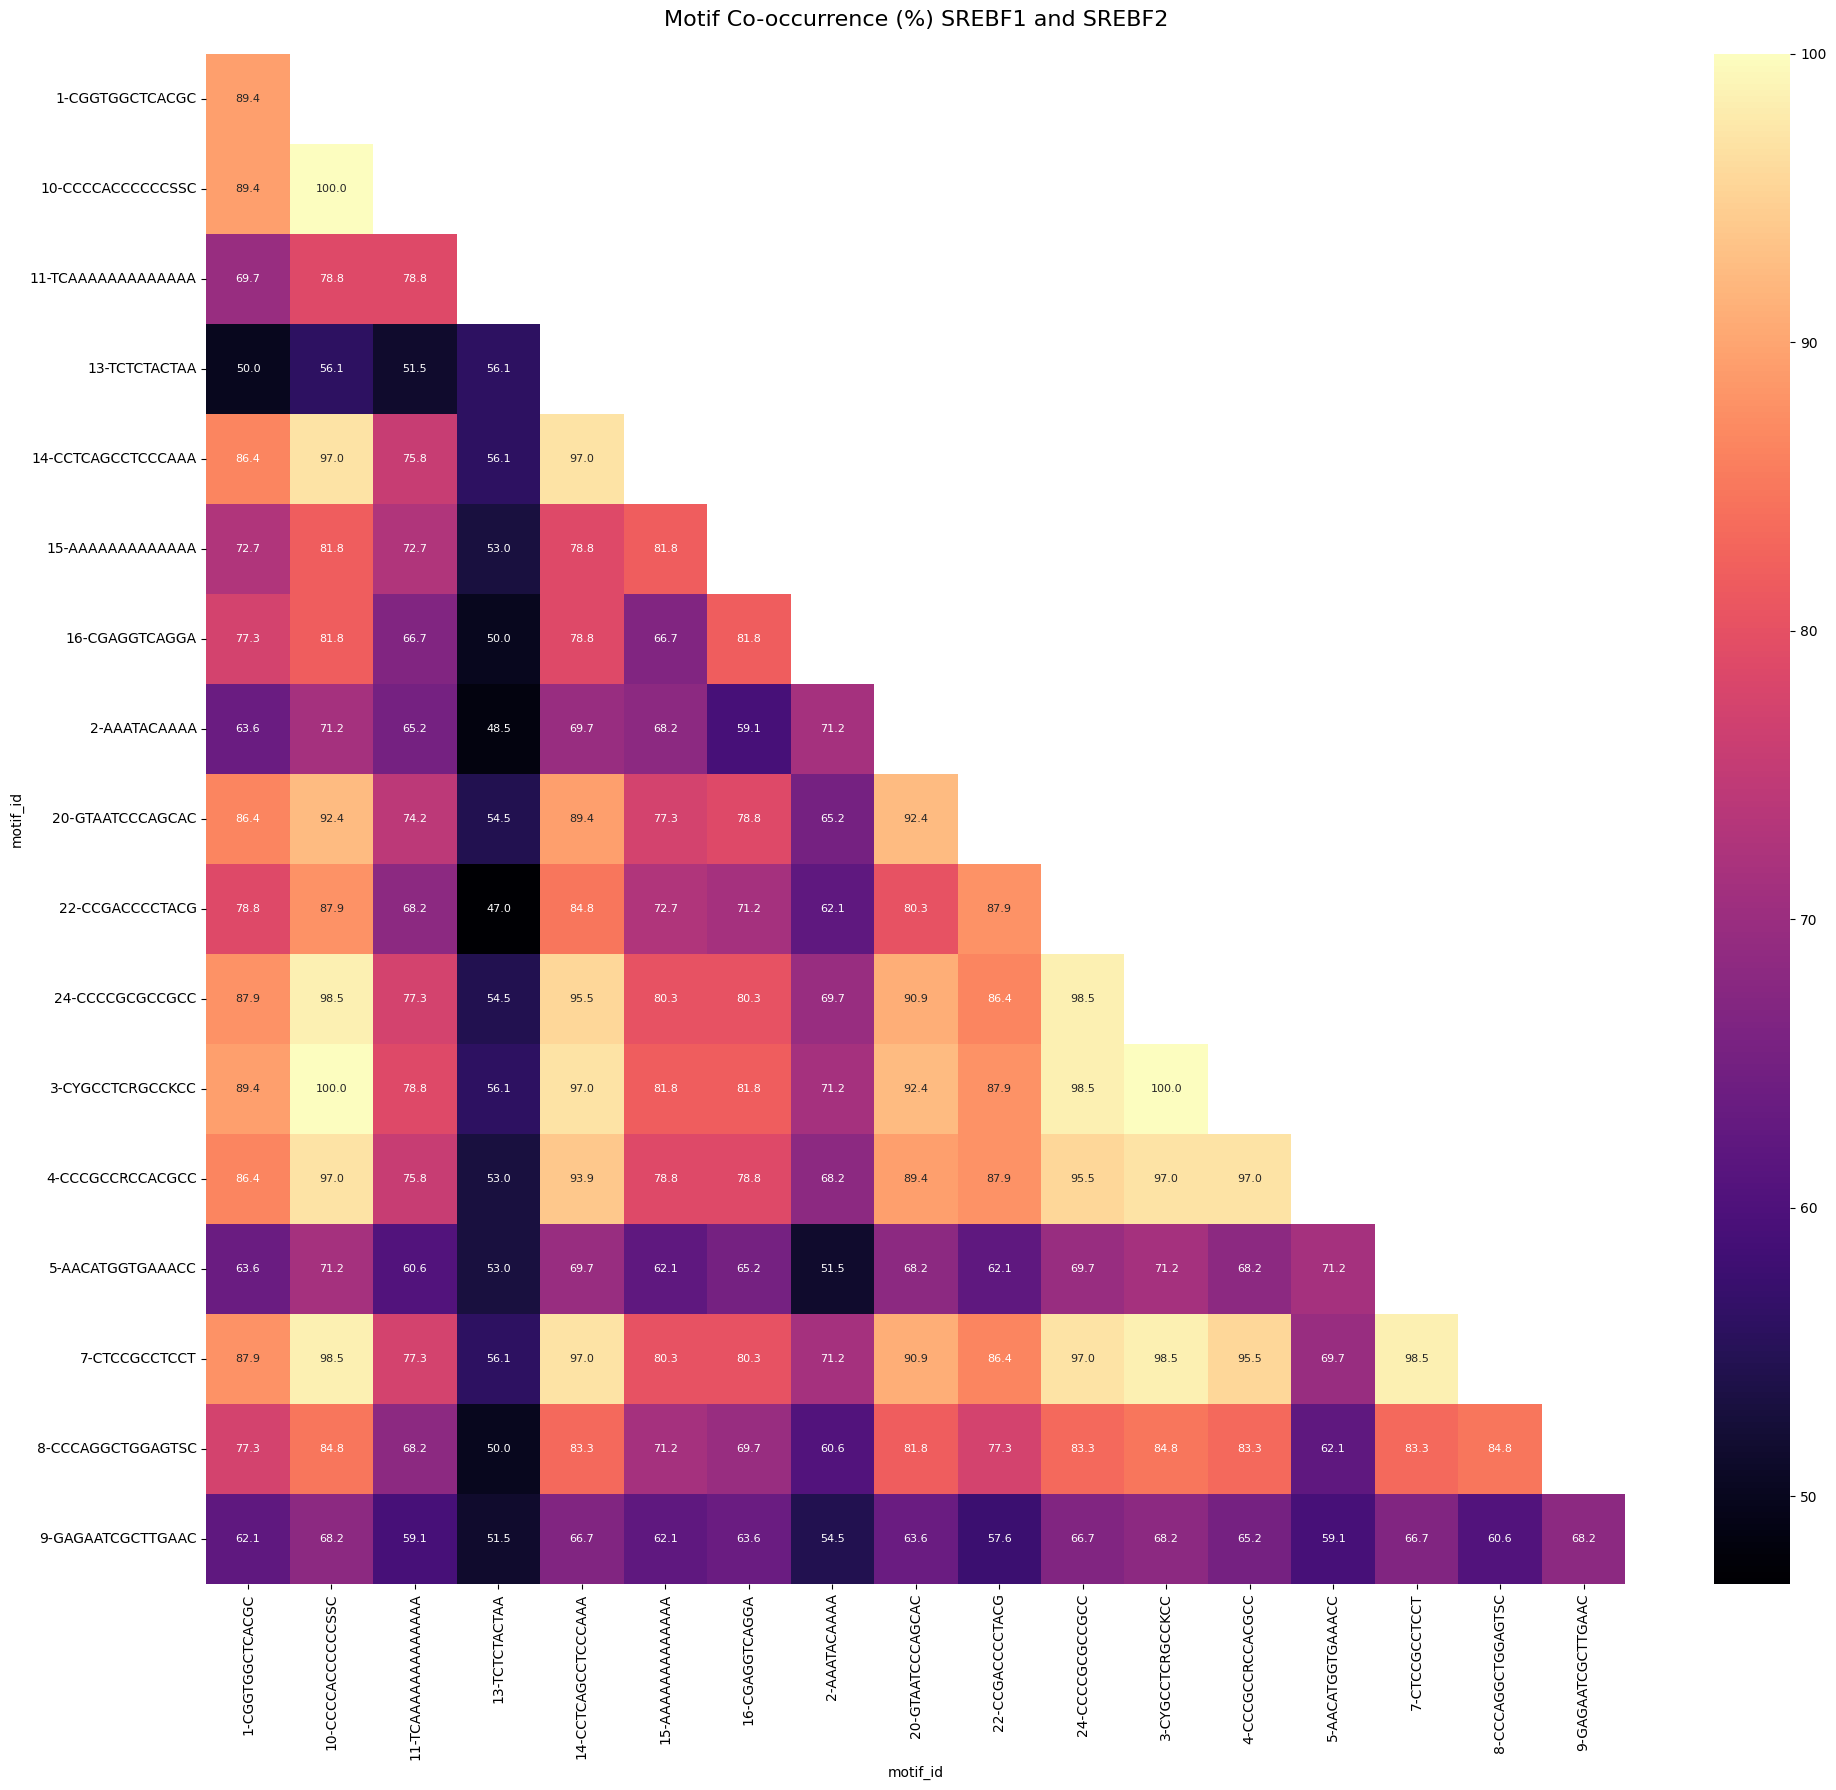

In [ ]:
heatmap_dia(mat3)

In [ ]:
#heatmap
def heatmap_dia3(co_df):
    import seaborn as sns
    import matplotlib.pyplot as plt
    import numpy as np

    #print only one half as it's mirror, excluding the diagonal from the mask
    mask = np.triu(np.ones_like(co_df, dtype=bool), k=1)
    plt.figure(figsize=(8,6)) # Increased figure size for better readability
    sns.heatmap(co_df, annot=True, cmap="magma", fmt=".1f", annot_kws={"fontsize":8}, mask=mask) # Reduced annotation font size
    plt.title("Motif Co-occurrence (%) SREBF2", fontsize=16, pad=20) # Centered title and increased font size
    plt.tight_layout() # Adjust layout to prevent labels from being cut off
    plt.show()

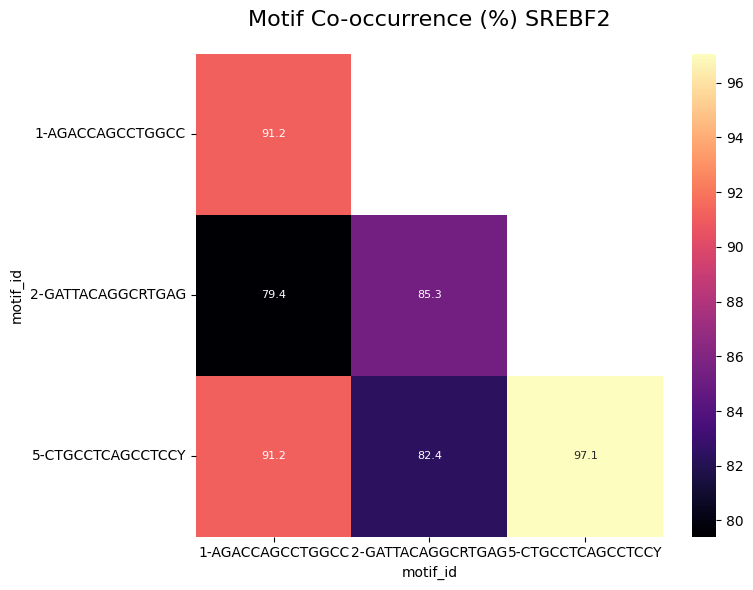

In [ ]:
heatmap_dia3(mat2)

In [ ]:
#stats
print("SREBF1 details")
stats(filepath)
print("\nSREBF2 details")
stats(filepath2)
print("\nSREBF1-2 details")
stats(filepath3)

SREBF1 details
No of motifs: 73
No of sequences: 1503

SREBF2 details
No of motifs: 3
No of sequences: 34

SREBF1-2 details
No of motifs: 17
No of sequences: 66


### Plotting Number of Promoters vs. Number of Motifs

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Load the presence data for SREBF1 (using the already defined filepath)
presence_df = load(filepath)

# Calculate the number of motifs for each promoter
promoter_motif_counts = presence_df.sum(axis=1)

# Get the maximum number of motifs found in any promoter
max_motifs = promoter_motif_counts.max()

# Prepare data for plotting: count promoters with at least 'k' motifs
plot_data = []
for k in range(1, max_motifs + 1):
    num_promoters_with_at_least_k_motifs = (promoter_motif_counts >= k).sum()
    plot_data.append({'Min Number of Motifs': k, 'Number of Promoters': num_promoters_with_at_least_k_motifs})

plot_df = pd.DataFrame(plot_data)

# Display the head of the data used for plotting
print("Data for plot (first 5 rows):")
display(plot_df.tail())


motif_id       1-CCACCACGCCCGGCY  10-AAAAAAAAAAAAAAA  11-AAAATACAAAAAT  \
sequence_name                                                            
AAGAB(-)                       1                   0                 1   
AANAT(+)                       1                   1                 1   
ABHD16A(-)                     1                   1                 1   
ABHD4(+)                       1                   1                 1   
ACACA(-)                       1                   1                 1   

motif_id       12-AGTGCAGTGGCG  13-GCAACCTCCGCCTCC  14-CAVGTGATC  \
sequence_name                                                      
AAGAB(-)                     0                   1             0   
AANAT(+)                     1                   1             1   
ABHD16A(-)                   1                   1             1   
ABHD4(+)                     1                   1             1   
ACACA(-)                     1                   1             1   

moti

,Min Number of Motifs,Number of Promoters
63,64,73
64,65,50
65,66,22
66,67,8
67,68,2


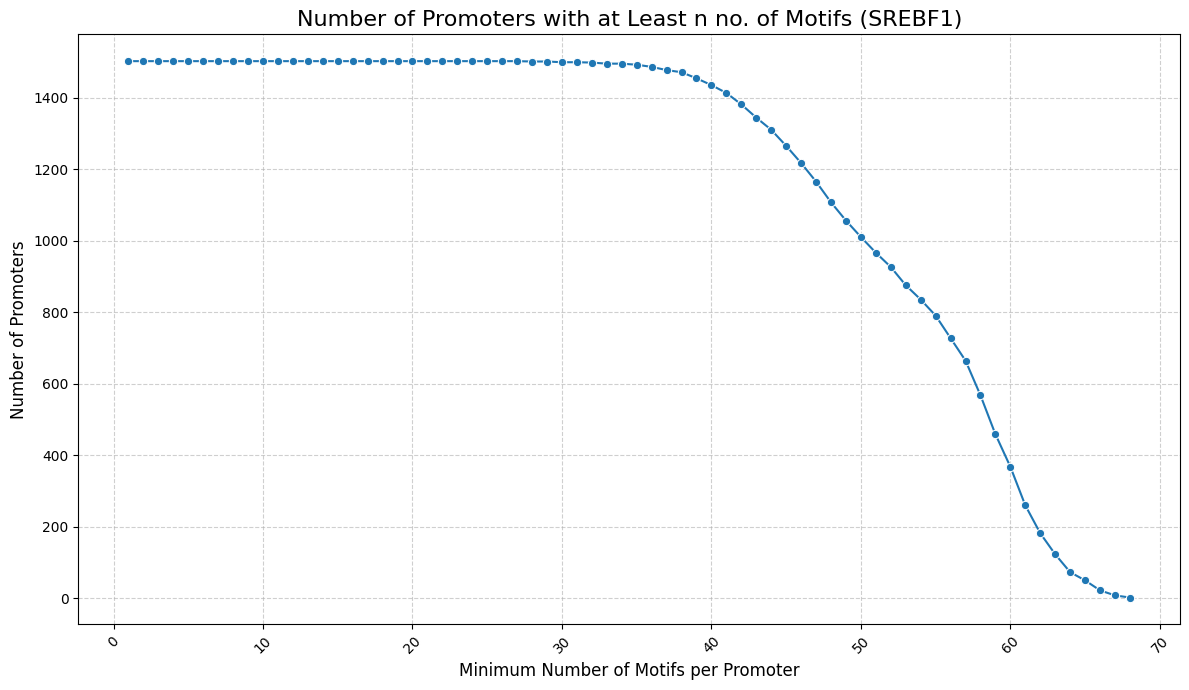


SREBF1 details
No of motifs: 73
No of sequences: 1503


In [ ]:
plt.figure(figsize=(12, 7))
sns.lineplot(x='Min Number of Motifs', y='Number of Promoters', data=plot_df, marker='o')
plt.title('Number of Promoters with at Least n no. of Motifs (SREBF1)', fontsize=16)
plt.xlabel('Minimum Number of Motifs per Promoter', fontsize=12)
plt.ylabel('Number of Promoters', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#print stats
print("\nSREBF1 details")
stats(filepath)


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Load the presence data for SREBF2 (using the already defined filepath)
presence_df_x = load(filepath2)

# Calculate the number of motifs for each promoter
promoter_motif_counts_x = presence_df_x.sum(axis=1)

# Get the maximum number of motifs found in any promoter
max_motifs_x = promoter_motif_counts_x.max()

# Prepare data for plotting: count promoters with at least 'k' motifs
plot_data_x = []
for k in range(1, max_motifs_x + 1):
    num_promoters_with_at_least_k_motifs_x = (promoter_motif_counts_x >= k).sum()
    plot_data_x.append({'Min Number of Motifs': k, 'Number of Promoters': num_promoters_with_at_least_k_motifs_x})

plot_df_x = pd.DataFrame(plot_data_x)

# Display the head of the data used for plotting
print("Data for plot (first 5 rows):")
display(plot_df_x.head())


motif_id       1-AGACCAGCCTGGCC  2-GATTACAGGCRTGAG  5-CTGCCTCAGCCTCCY
sequence_name                                                        
ALKBH7(+)                     1                  1                  1
ALOX12B(-)                    1                  1                  1
AMACR(-)                      1                  1                  1
BRIX1(+)                      1                  1                  1
CCDC107(+)                    1                  1                  1
Data for plot (first 5 rows):


,Min Number of Motifs,Number of Promoters
0,1,34
1,2,32
2,3,27


In [ ]:
#srebf2 stats
print("\nSREBF2 details")
stats(filepath2)


SREBF2 details
No of motifs: 3
No of sequences: 34


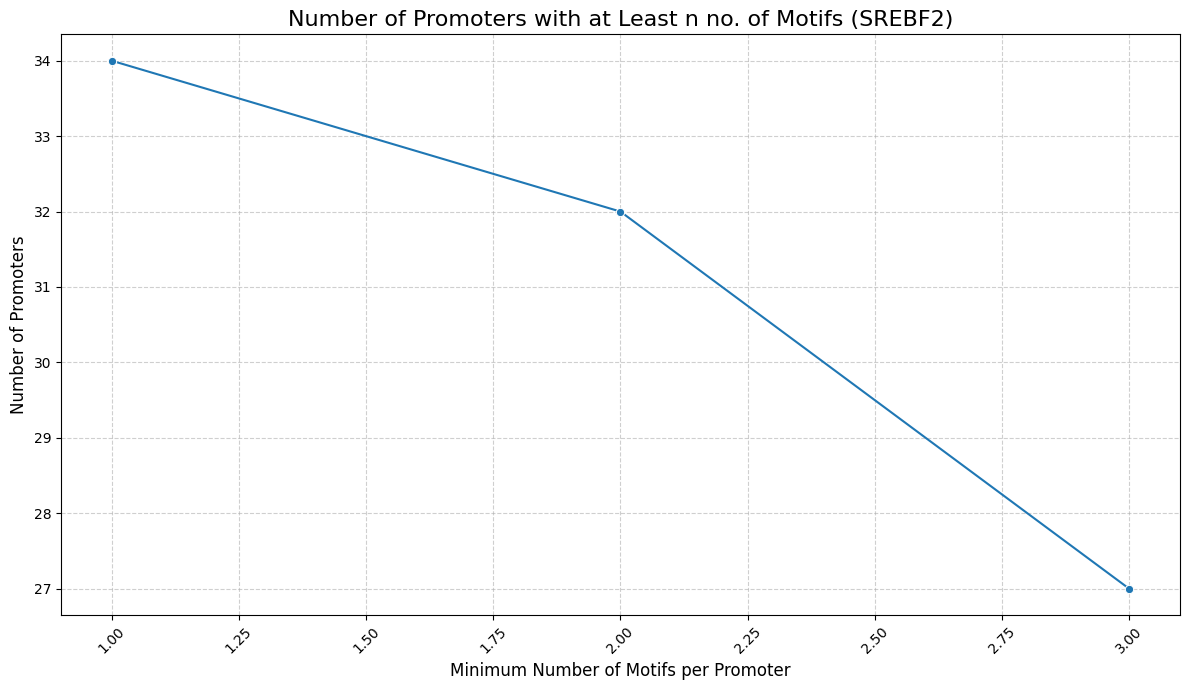

In [ ]:
plt.figure(figsize=(12, 7))
sns.lineplot(x='Min Number of Motifs', y='Number of Promoters', data=plot_df_x, marker='o')
plt.title('Number of Promoters with at Least n no. of Motifs (SREBF2)', fontsize=16)
plt.xlabel('Minimum Number of Motifs per Promoter', fontsize=12)
plt.ylabel('Number of Promoters', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Load the presence data for SREBF2 (using the already defined filepath)
presence_df3 = load(filepath3)

# Calculate the number of motifs for each promoter
promoter_motif_counts3 = presence_df3.sum(axis=1)

# Get the maximum number of motifs found in any promoter
max_motifs3 = promoter_motif_counts3.max()

# Prepare data for plotting: count promoters with at least 'k' motifs
plot_data3 = []
for k in range(1, max_motifs3 + 1):
    num_promoters_with_at_least_k_motifs = (promoter_motif_counts3 >= k).sum()
    plot_data3.append({'Min Number of Motifs': k, 'Number of Promoters': num_promoters_with_at_least_k_motifs})

plot_df3 = pd.DataFrame(plot_data3)

# Display the head of the data used for plotting
print("Data for plot (first 5 rows):")
display(plot_df3.head())


motif_id       1-CGGTGGCTCACGC  10-CCCCACCCCCCSSC  11-TCAAAAAAAAAAAAA  \
sequence_name                                                           
APTX(-)                      1                  1                   0   
C19orf25(-)                  1                  1                   1   
C6orf62(-)                   1                  1                   1   
CAVIN1(-)                    1                  1                   1   
CHAF1A(+)                    1                  1                   1   

motif_id       13-TCTCTACTAA  14-CCTCAGCCTCCCAAA  15-AAAAAAAAAAAAA  \
sequence_name                                                        
APTX(-)                    0                   1                 1   
C19orf25(-)                1                   1                 1   
C6orf62(-)                 1                   1                 1   
CAVIN1(-)                  1                   1                 1   
CHAF1A(+)                  1                   1                 1  

,Min Number of Motifs,Number of Promoters
0,1,66
1,2,66
2,3,66
3,4,66
4,5,66


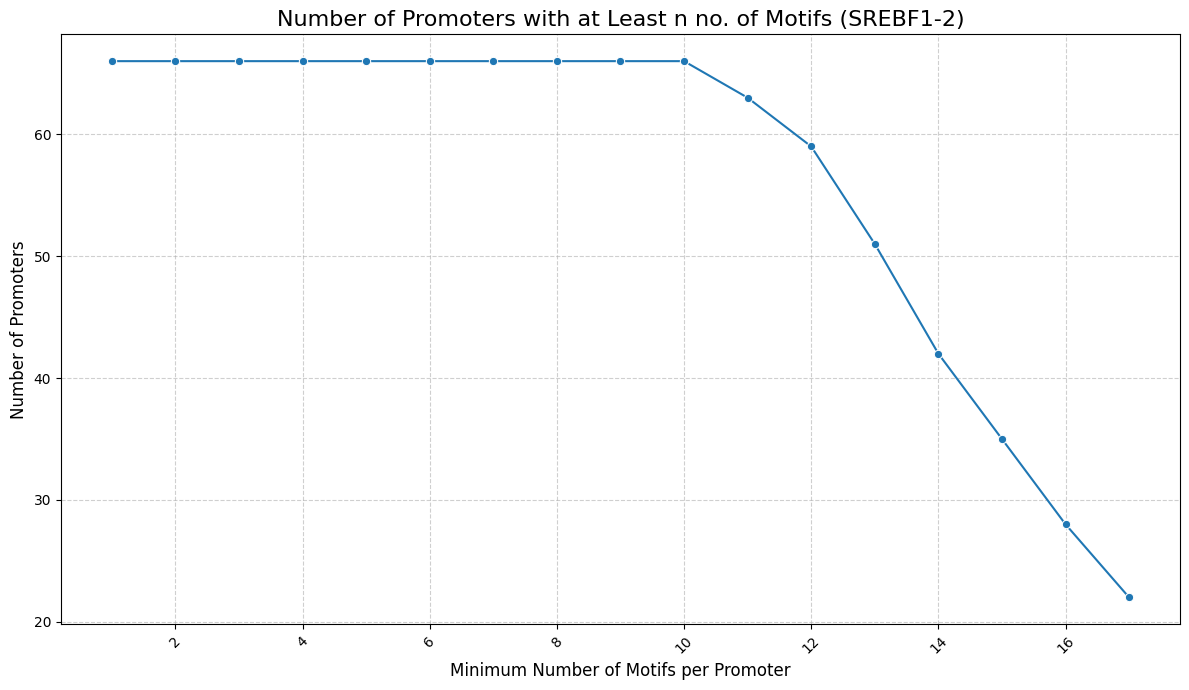


SREBF1-2 details
No of motifs: 17
No of sequences: 66


In [ ]:
plt.figure(figsize=(12, 7))
sns.lineplot(x='Min Number of Motifs', y='Number of Promoters', data=plot_df3, marker='o')
plt.title('Number of Promoters with at Least n no. of Motifs (SREBF1-2)', fontsize=16)
plt.xlabel('Minimum Number of Motifs per Promoter', fontsize=12)
plt.ylabel('Number of Promoters', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#print no. of motifs
print("\nSREBF1-2 details")
stats(filepath3)
